In [1]:
import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image

In [2]:
def detect_blue_object(`img`, threshold=250):
    image = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    # maps
    maps = image.copy()
    blue_map = maps[:,:,-1]
    red_map = maps[:, :, 0]
    green_map = maps[:, :, 1]

    blue_mask = (blue_map >= 250) & (red_map <= 200) & (green_map <= 200)
    mask_white_and_black = Image.fromarray(blue_mask)
    bbox = mask_white_and_black.getbbox()

    if bbox is not None:
        x1, y1, x2, y2 = bbox
        object_detected = cv2.rectangle(
            image,
            pt1=(x1, y1),
            pt2=(x2, y2),
            color=(0,255,0),
            thickness=5)

    else:
        object_detected = image

    return cv2.cvtColor(object_detected, cv2.COLOR_RGB2BGR)





In [3]:
cam = cv2.VideoCapture(0)

while True:
    check, frame = cam.read()

    cv2.imshow('video', detect_blue_object(frame))
    image_test = frame
    key = cv2.waitKey(1)
    if cv2.waitKey(1) & 0xFF == ord('q'):
        break

cam.release()
cv2.destroyAllWindows()

[ WARN:0@2.699] global cap_v4l.cpp:914 open VIDEOIO(V4L2:/dev/video0): can't open camera by index
[video4linux2,v4l2 @ 0x555e60a0ce40] ioctl(VIDIOC_G_INPUT): Inappropriate ioctl for device
[ERROR:0@2.700] global obsensor_uvc_stream_channel.cpp:163 getStreamChannelGroup Camera index out of range


NameError: name 'cam' is not defined

In [5]:
image = cv2.cvtColor(image_test, cv2.COLOR_BGR2RGB)

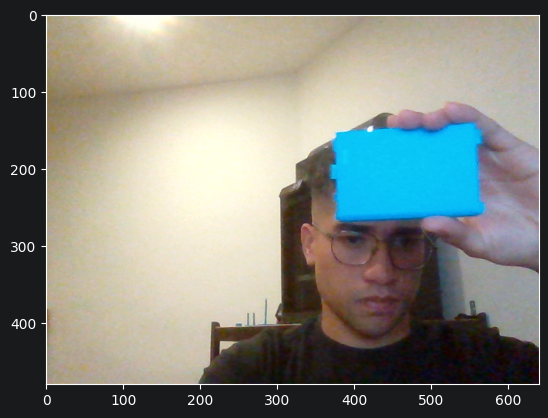

In [6]:
plt.imshow(image)

/tmp/ipykernel_39661/3255693923.py:7: MatplotlibDeprecationWarning: Passing the range parameter of hist() positionally is deprecated since Matplotlib 3.10; the parameter will become keyword-only in 3.12.
  ax.hist(img.ravel(), 256, [0,256], label=colors[i], color=colors[i], alpha=0.7)


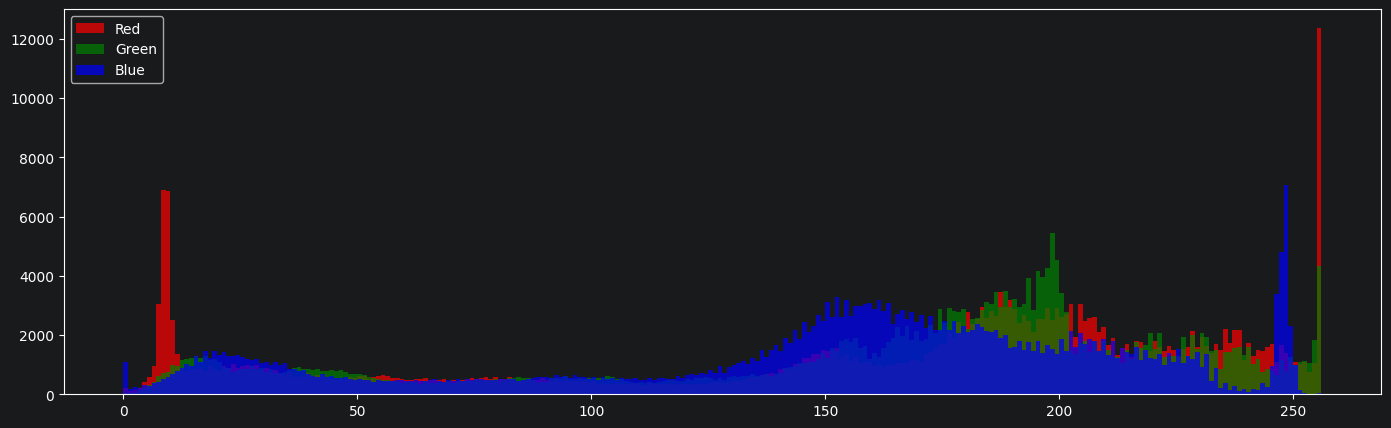

In [7]:
figure, ax = plt.subplots(1, 1, figsize=(17, 5), sharey=True)
colors = ['Red', 'Green', 'Blue']


for i in range(3):
    img = image[:,:, i]
    ax.hist(img.ravel(), 256, [0,256], label=colors[i], color=colors[i], alpha=0.7)
    ax.legend()

In [53]:
blue_map = image[:, :, -1]
red_map = image[:, :, 0]
green_map =image[:, :, 1]

In [41]:
index_to_find = np.argwhere((blue_map >= 250) & (red_map <= 245))

In [63]:
blue_mask = (blue_map >= 245) & (red_map <= 200) & (green_map <= 200)

In [67]:
from PIL import Image

In [69]:
mask_wb = Image.fromarray(blue_mask)

In [70]:
mask_wb.getbbox()

(372, 143, 568, 263)

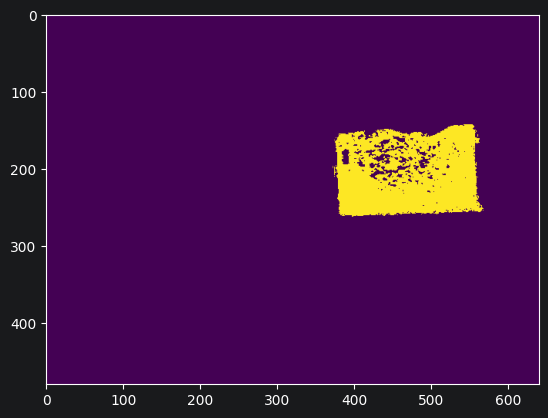

In [65]:
plt.imshow(blue_mask)

In [42]:
index_to_find.size

2468

In [21]:
index_to_find.sort()

In [11]:
index_to_find[0][1]

np.int64(104)

In [12]:
index_to_find[-1]

array([262, 398])

In [13]:
(index_to_find[0][1], index_to_find[0][0])

(np.int64(104), np.int64(0))

In [19]:
index_to_find.shape

19770

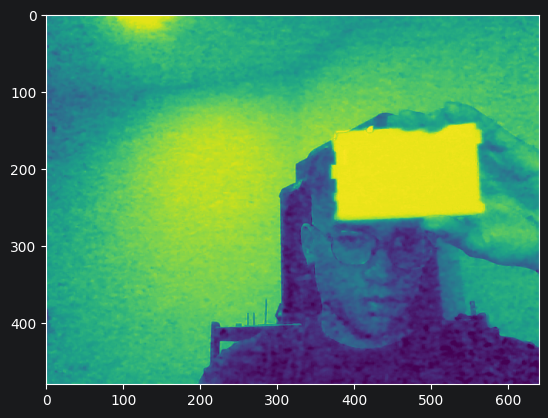

In [14]:
plt.imshow(blue_map)

In [195]:
(index_to_find[0][1], index_to_find[0][0])

(np.int64(492), np.int64(140))

In [ ]:
numpy.arr

In [1]:
index_to_find

NameError: name 'index_to_find' is not defined

In [196]:
(index_to_find[1][1], index_to_find[1][0])

(np.int64(484), np.int64(141))

In [198]:
object_detected = cv2.rectangle(image,pt1=(index_to_find[0][1], index_to_find[0][0]) ,pt2=(index_to_find[-1][1], index_to_find[-1][0]),color=(0,255,0),thickness=5)


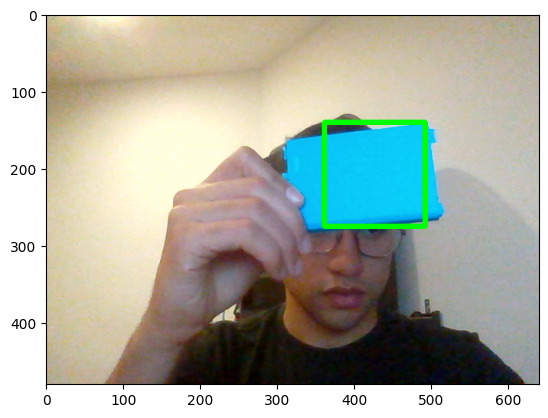

In [199]:
plt.imshow(object_detected)